# Modelo estructurado: polaridad por cláusula + estructura del discurso

## Por qué

En las reseñas mixtas (una opinión positiva y una negativa) la etiqueta depende de una **interacción**: la polaridad de cada opinión × el conector que la introduce × su posición. Por ejemplo, después de "al final" o "aun así" manda la opinión que sigue, mientras que "por cierto" o "de paso" introducen un comentario secundario. Un modelo lineal sobre n-gramas no puede representar esas interacciones, y por eso se estanca cerca de 0.89–0.90.

## Cómo

1. **Segmentación en cláusulas.** Cada reseña se divide en cláusulas, guardando el conector que introduce cada una y la polaridad que le asignan las reglas (frases fijas y adjetivos con negación).
2. **Clasificador de polaridad por cláusula con supervisión débil.** No hay etiquetas por cláusula, así que se construyen:
   - las cláusulas de reseñas neutrales son "ninguna" opinión;
   - la cláusula que sigue a un conector decisivo hereda la etiqueta de la reseña;
   - las cláusulas con polaridad según las reglas toman esa polaridad.

   Con n-gramas de caracteres el clasificador generaliza a errores de tipeo ("microofono") y a frases que las listas no cubren.
3. **Rasgos de estructura del discurso por reseña:** polaridad, confianza, conector y posición de las últimas opiniones y de la primera, la polaridad tras el último conector decisivo, conteos, etc.
4. **Stacking:** gradient boosting sobre los rasgos de estructura más las probabilidades de un modelo de texto (regresión logística sobre el preprocesador de `model_training.ipynb`). El boosting aprende las interacciones que el modelo lineal no puede.

Todo lo que usa etiquetas (conectores decisivos, clasificador de cláusulas, modelo de texto) se ajusta con **validación cruzada por folds** para generar los rasgos de train sin fuga de información, y con todo train para el test. No se usan redes neuronales.

In [1]:
import re
import time
import nltk
import numpy as np
import pandas as pd
import scipy.sparse as sp
import matplotlib.pyplot as plt
from joblib import Parallel, delayed
from imblearn.pipeline import Pipeline
from nltk.corpus import stopwords
from nltk.stem import SnowballStemmer
from nltk.tokenize import word_tokenize
from sklearn.compose import ColumnTransformer
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.feature_extraction.text import CountVectorizer, TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, classification_report, ConfusionMatrixDisplay
from sklearn.model_selection import StratifiedKFold, cross_val_predict, train_test_split
from sklearn.preprocessing import FunctionTransformer

nltk.download("punkt_tab", quiet=True)
nltk.download("stopwords", quiet=True)

True

In [2]:
data = pd.read_csv("data/train.csv")
X = data.drop("label", axis=1)
y = data["label"]

# Mismo split que model_training.ipynb
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)
print(f"Train: {len(X_train)} | Test: {len(X_test)}")

Train: 9600 | Test: 2400


## Preprocesamiento y reglas de opinión

Las funciones de `model_training.ipynb`: normalización, stopwords, negación, el preprocesador TF-IDF y las listas de frases y adjetivos de opinión del generador.

In [3]:
import unicodedata


def quitar_tildes(text):
    """Elimina tildes y diéresis, pues muchas reseñas están escritas sin ellas."""
    return unicodedata.normalize("NFKD", text).encode("ascii", "ignore").decode("ascii")


spanish_stopwords_completas = set(stopwords.words("spanish"))

palabras_negativas = {
    "no",
    "nunca",
    "jamás",
    "nadie",
    "ninguno",
    "poco",
    "ni",
    "pero",
    "sin",
    "muy",
    "más",
    "mucho",
    "nada",
    "contra",
    "algo",
}

# Se comparan sin tildes porque el texto también se normaliza sin tildes
spanish_stopwords = {
    quitar_tildes(w) for w in spanish_stopwords_completas - palabras_negativas
}

# Lista mínima (artículos, preposiciones y pronombres) para no romper frases hechas como "con los ojos cerrados"
stopwords_minimas = {
    quitar_tildes(w)
    for w in [
        "el",
        "la",
        "los",
        "las",
        "un",
        "una",
        "unos",
        "unas",
        "de",
        "del",
        "al",
        "y",
        "o",
        "e",
        "a",
        "en",
        "que",
        "lo",
        "le",
        "les",
        "se",
        "me",
        "mi",
        "mis",
        "su",
        "sus",
    ]
}

print(f"Cantidad de stopwords en español: {len(spanish_stopwords)}")
print(f"Contiene no: {'no' in spanish_stopwords}")

Cantidad de stopwords en español: 295
Contiene no: False


In [4]:
stemmer = SnowballStemmer("spanish")

# Palabras que niegan lo que viene después de ellas (sin tildes, como el texto normalizado)
NEGADORES = {
    "no",
    "nunca",
    "jamas",
    "ni",
    "nada",
    "sin",
    "tampoco",
    "nadie",
    "ninguno",
    "ninguna",
}
# Tokens que cierran el alcance de una negación: puntuación y conectores adversativos
FIN_NEGACION = {".", ",", ";", ":", "!", "?", "pero", "aunque", "sino"}
NEG_PREFIX = "NEG_"


def marcar_negacion(tokens):
    """Agrega el prefijo NEG_ a las palabras dentro del alcance de una negación, es decir,
    desde el negador hasta el siguiente signo de puntuación o conector adversativo."""
    marcados, negando = [], False
    for t in tokens:
        if t in FIN_NEGACION:
            negando = False
        elif t in NEGADORES:
            negando = True
        elif negando:
            t = NEG_PREFIX + t
        marcados.append(t)
    return marcados


def tokenizer_stemmer(text, stopwords=spanish_stopwords, stemming=True):
    """Hacemos el preprocesamiento del texto: normalización, tokenización, marcado de negación y stemming en una sola función para luego pasarlo al pipeline de procesamiento."""
    tokens = marcar_negacion(word_tokenize(quitar_tildes(text.lower())))
    resultado = []
    for t in tokens:
        palabra = t.removeprefix(NEG_PREFIX)
        if palabra.isalpha() and palabra not in stopwords:
            prefijo = NEG_PREFIX if t.startswith(NEG_PREFIX) else ""
            resultado.append(prefijo + (stemmer.stem(palabra) if stemming else palabra))
    return resultado

In [5]:
import re
from collections import Counter, defaultdict
from functools import partial

TEXT_COLUMN = "text"
COLUMN_LAST_SENTENCE = "last_sentence"
COLUMN_CONTRAST = "after_contrast"
TARGET_COLUMN = "label"

VECTORIZERS = {
    "count": CountVectorizer,
    "tfidf": TfidfVectorizer,
}


def extract_last_sentences(text, n_sentences):
    """Extrae las últimas n_sentences oraciones no vacías de un texto."""
    sentences = [s.strip() for s in text.split(".") if s.strip()]
    return ". ".join(sentences[-n_sentences:]) if sentences else ""


def add_last_sentences(X, n_sentences=1):
    """Agrega la columna con la última oración del texto, conservando las columnas originales."""
    return X.assign(
        **{
            COLUMN_LAST_SENTENCE: X[TEXT_COLUMN].apply(
                lambda x: extract_last_sentences(x, n_sentences)
            )
        }
    )


# Conectores tras los cuales suele estar la opinión que define la reseña: "La pantalla es mala. Eso sí, la batería es excelente".
# "por otro lado", "en cambio" y "en general" no se incluyen porque la cláusula que sigue no predice mejor la etiqueta que la anterior.
CONECTORES_CONTRASTE = [
    "pero",
    "sin embargo",
    "aunque",
    "no obstante",
    "aun asi",
    "con todo",
    "lo que si",
    "a fin de cuentas",
    "al final"
]
PATRON_CONTRASTE = re.compile(r"\b(?:" + "|".join(CONECTORES_CONTRASTE) + r")\b")


def extract_after_contrast(text):
    """Extrae la oración que sigue al último conector de contraste, o una cadena vacía si no hay ninguno."""
    normalizado = quitar_tildes(text.lower())
    coincidencias = list(PATRON_CONTRASTE.finditer(normalizado))
    if not coincidencias:
        return ""
    return normalizado[coincidencias[-1].end() :].split(".")[0].strip(" ,")


def add_after_contrast(X):
    """Agrega la columna con la oración posterior al último conector de contraste, conservando las columnas originales."""
    return X.assign(**{COLUMN_CONTRAST: X[TEXT_COLUMN].apply(extract_after_contrast)})


def remove_first_sentence(X):
    """Elimina la primera oración del texto, conservando las columnas originales."""

    def first_sentence_removed(text):
        sentences = [s.strip() for s in text.split(".") if s.strip()]
        return ". ".join(sentences[1:]) if len(sentences) > 1 else ""

    return X.assign(**{TEXT_COLUMN: X[TEXT_COLUMN].apply(first_sentence_removed)})


def split_sentences(text):
    """Divide el texto en oraciones no vacías."""
    return [s.strip() for s in text.split(".") if s.strip()]


def normalize_sentence(sentence):
    """Normaliza una oración para compararla con otras: minúsculas, sin tildes y sin comas en los extremos."""
    return quitar_tildes(sentence.lower()).strip(" ,")




def vectorizer_function(
    vectorizer="count",
    ngram_range=(1, 3),
    stopwords=spanish_stopwords,
    stemming=True,
    sublinear_tf=False,
    min_df=1,
):
    """Vectorizador de palabras con el tokenizador propio. sublinear_tf (1 + log(tf)) solo existe en TF-IDF,
    por eso se pasa únicamente a TfidfVectorizer."""
    tfidf_kwargs = {"sublinear_tf": sublinear_tf} if vectorizer == "tfidf" else {}
    return VECTORIZERS[vectorizer](
        tokenizer=partial(tokenizer_stemmer, stopwords=stopwords, stemming=stemming),
        token_pattern=None,
        ngram_range=ngram_range,
        min_df=min_df,
        **tfidf_kwargs,
    )




def build_preprocessor(
    vectorizer="count",
    ngram_range=(1, 3),
    stopwords=spanish_stopwords,
    stemming=True,
    sublinear_tf=False,
    min_df=1,
):
    """Construye el preprocesador de las features con el vectorizador indicado: 'count' o 'tfidf'.

    1. Crea la columna con la última oración y la columna con la oración posterior al último conector de contraste.
    2. Opcionalmente elimina la primera oración del texto completo (por defecto no la elimina;
       en el grid search se prueba con FunctionTransfomer(remove_first_sentence)).
    3. Vectoriza por separado el texto completo, la última oración y la oración posterior al contraste.
       ngram_range, stopwords, sublinear_tf y min_df controlan los tres vectorizadores de palabras.
    """
    word_vectorizer = partial(
        vectorizer_function, vectorizer, ngram_range, stopwords, stemming, sublinear_tf, min_df
    )
    vectorizers = [
        ("text_vectorizer", word_vectorizer(), TEXT_COLUMN,),
        ("last_sentence_vectorizer", word_vectorizer(), COLUMN_LAST_SENTENCE),
        ("contrast_vectorizer", word_vectorizer(), COLUMN_CONTRAST),
    ]
    steps = []
    return Pipeline(
        steps
        + [
            (
                "last_sentence",
                FunctionTransformer(add_last_sentences, kw_args={"n_sentences": 1}),
            ),
            ("after_contrast", FunctionTransformer(add_after_contrast)),
            ("remove_first_sentence", FunctionTransformer(remove_first_sentence)),
            ("vectorizers", ColumnTransformer(vectorizers)),
        ]
    )

In [6]:
import re

# Vocabulario del generador de reseñas: aspectos del producto y frases de opinión fijas
ASPECTOS = [
    "duracion de la bateria", "atencion al cliente", "resistencia al agua", "nitidez de la imagen", "manual de uso",
    "boton de encendido", "sistema de sonido", "sistema de carga", "app del fabricante", "menu de ajustes",
    "relacion calidad-precio", "relacion calidad precio", "calidad de sonido", "calidad de imagen", "cable de carga",
    "calidad de construccion", "calidad del sonido", "pantalla", "empaque", "precio", "cargador", "instalacion",
    "tamano", "control", "acabado", "bateria", "construccion", "correa", "autonomia", "procesador", "resolucion",
    "peso", "portabilidad", "camara", "senal", "ensamblaje", "velocidad", "ventilador", "sonido", "aplicacion",
    "motor", "material", "microfono", "conexion", "rendimiento", "teclado", "soporte", "carcasa", "funda",
    "terminacion", "tapa", "memoria", "comodidad", "ergonomia", "cable", "interfaz", "diseno", "color", "calidad",
]
PATRON_ASPECTO = re.compile(r"\b(" + "|".join(sorted(map(re.escape, ASPECTOS), key=len, reverse=True)) + r")\b")

FRASES_NEGATIVAS = [
    "no vale lo que cuesta", "me decepciono", "por debajo de la media", "se queda muy corto", "se queda corto",
    "se dano antes", "no es para nada lo que esperaba", "defraudo todas mis expectativas", "tire el dinero",
    "funciona bastante mal", "dolor de cabeza", "me arrepiento", "no le recomiendo", "error de compra",
    "quede muy molesto", "no volveria a comprar", "una estrella", "no pare de tener problemas", "arrepentido",
    "termine harto",
]
FRASES_POSITIVAS = [
    "justo lo que estaba buscando", "vale totalmente la pena", "fue todo un acierto", "me encanto",
    "funciona de maravilla", "respondio tal como esperaba", "supero todas mis expectativas", "cumple de sobra",
    "por encima de la media", "me alegra haber elegido", "me sorprendio para bien", "me hizo la vida mas facil",
    "termine feliz", "estoy feliz", "quede encantado", "con los ojos cerrados", "volveria a comprar",
    "ni una sola queja", "cinco estrellas",
]


# Adjetivos de la plantilla "<aspecto> es/resultó/me salió <adjetivo>"
ADJETIVOS_POSITIVOS = [
    "funcional", "resistente", "impecable", "sobresaliente", "veloz", "confiable", "excelente", "eficiente",
    "formidable", "fiable", "potente", "superior", "decente", "notable", "espectacular", "durable", "practica",
    "practico", "cumplidor", "cumplidora", "agradable", "comodisima", "comodisimo", "buenisima", "buenisimo",
    "rapidisima", "rapidisimo", "comoda", "comodo", "optimo", "optima", "correcta", "correcto", "solida", "solido",
    "redonda", "redondo", "ligera", "ligero", "completa", "completo", "robusta", "robusto", "buena", "bueno",
    "nitida", "nitido", "precisa", "preciso", "estupenda", "estupendo", "bien hecha", "bien hecho", "bien logrado",
    "bien lograda", "bien construida", "bien construido",
]
ADJETIVOS_NEGATIVOS = [
    "torpe", "pobre", "terrible", "decepcionante", "endeble", "debil", "desagradable", "fragil", "corriente",
    "inestable", "deficiente", "mediocre", "inconsistente", "olvidable", "incumplidor", "incumplidora", "ruidosa",
    "ruidoso", "imprecisa", "impreciso", "delicada", "delicado", "lentisima", "lentisimo", "pesima", "pesimo",
    "malisima", "malisimo", "flojo", "floja", "ordinaria", "ordinario", "aparatoso", "aparatosa", "chapucera",
    "chapucero", "basica", "basico", "incomoda", "incomodo", "limitado", "limitada", "defectuosa", "defectuoso",
    "mal terminada", "mal terminado", "mal construida", "mal construido", "mal hecha", "mal hecho",
]
PATRON_ADJ_POSITIVO = re.compile(r"\b(?:" + "|".join(ADJETIVOS_POSITIVOS) + r")\b")
PATRON_ADJ_NEGATIVO = re.compile(r"\b(?:" + "|".join(ADJETIVOS_NEGATIVOS) + r")\b")


def polaridad_clausula(clausula):
    """+1, -1 o 0. Primero busca las frases fijas (las negativas antes, por "no volveria a comprar")
    y si no hay ninguna, compara cuántos adjetivos positivos y negativos tiene."""
    if any(f in clausula for f in FRASES_NEGATIVAS):
        return -1
    if any(f in clausula for f in FRASES_POSITIVAS):
        return 1
    puntaje = len(PATRON_ADJ_POSITIVO.findall(clausula)) - len(PATRON_ADJ_NEGATIVO.findall(clausula))
    return int(np.sign(puntaje))

CONECTORES = sorted(
    ["sin embargo", "eso si", "aun asi", "lo que si", "no obstante", "a fin de cuentas", "al final", "con todo",
     "por otro lado", "por cierto", "de paso", "ademas", "ahora", "pero", "aunque", "y", "la verdad"],
    key=len, reverse=True,
)
SEPARADOR_CLAUSULAS = re.compile(
    r"([.;!?]|,?\s\b(?:pero|aunque|sin embargo|eso si|aun asi|lo que si|no obstante|y)\b)"
)


def extraer_opiniones(texto):
    """Lista de (aspecto, polaridad, conector) de cada cláusula que menciona un aspecto con una opinión.
    El conector es el que aparece justo antes o al inicio de la cláusula ("" si no hay)."""
    partes = SEPARADOR_CLAUSULAS.split(quitar_tildes(texto.lower()))
    opiniones, separador = [], ""
    for i in range(0, len(partes), 2):
        clausula = partes[i].strip(" ,")
        aspectos = PATRON_ASPECTO.findall(clausula)
        polaridad = polaridad_clausula(clausula) if aspectos else 0
        if polaridad:
            contexto = separador + " " + clausula[:30]
            conector = next((c for c in CONECTORES if re.search(rf"\b{c}\b", contexto)), "")
            opiniones.append((aspectos[0], polaridad, conector))
        separador = partes[i + 1] if i + 1 < len(partes) else ""
    return opiniones

## 1. Segmentación en cláusulas

A diferencia de `extraer_opiniones`, aquí una cláusula no necesita mencionar un aspecto de la lista para tener opinión ("Volvería a comprarlo sin pensarlo"), y la negación invierte los adjetivos ("nada flojo" es positivo).

In [7]:
ADJ_POS_SIMPLES = {a for a in ADJETIVOS_POSITIVOS if " " not in a}
ADJ_NEG_SIMPLES = {a for a in ADJETIVOS_NEGATIVOS if " " not in a}
ADJ_POS_COMPUESTOS = [a for a in ADJETIVOS_POSITIVOS if " " in a]
ADJ_NEG_COMPUESTOS = [a for a in ADJETIVOS_NEGATIVOS if " " in a]


def polaridad_por_reglas(clausula):
    """+1, -1 o 0 según las frases fijas y, si no hay, los adjetivos (invertidos dentro de una negación)."""
    if any(f in clausula for f in FRASES_NEGATIVAS):
        return -1
    if any(f in clausula for f in FRASES_POSITIVAS):
        return 1
    puntaje = sum(a in clausula for a in ADJ_POS_COMPUESTOS) - sum(a in clausula for a in ADJ_NEG_COMPUESTOS)
    negando = False
    for palabra in re.findall(r"[a-z]+", clausula):
        if palabra in NEGADORES:
            negando = True
            continue
        polaridad = (palabra in ADJ_POS_SIMPLES) - (palabra in ADJ_NEG_SIMPLES)
        puntaje += -polaridad if negando else polaridad
    return int(np.sign(puntaje))


def segmentar(texto):
    """Lista de (cláusula, conector que la introduce, polaridad por reglas)."""
    partes = SEPARADOR_CLAUSULAS.split(quitar_tildes(texto.lower()))
    clausulas, separador = [], ""
    for i in range(0, len(partes), 2):
        clausula = partes[i].strip(" ,")
        if clausula:
            contexto = separador + " " + clausula[:30]
            conector = next((c for c in CONECTORES if re.search(rf"\b{c}\b", contexto)), "")
            clausulas.append((clausula, conector, polaridad_por_reglas(clausula)))
        separador = partes[i + 1] if i + 1 < len(partes) else ""
    return clausulas


clausulas_train = X_train["text"].apply(segmentar)
clausulas_test = X_test["text"].apply(segmentar)
segmentar("Llegó sin contratiempos. Me decepcionó la pantalla. Al final, el empaque quedó correcto, nada flojo.")

[('llego sin contratiempos', '', 0),
 ('me decepciono la pantalla', '', -1),
 ('al final, el empaque quedo correcto, nada flojo', 'al final', 1)]

## 2. Clasificador de polaridad por cláusula (supervisión débil)

In [8]:
def conectores_decisivos(clausulas, etiquetas, precision_minima=0.98, resenas_minimas=30):
    """Conectores tras los cuales la última opinión coincide con la etiqueta en al menos precision_minima de los casos."""
    filas = []
    for cl, etiqueta in zip(clausulas, etiquetas):
        opiniones = [(conector, p) for _, conector, p in cl if p]
        if opiniones:
            conector, p = opiniones[-1]
            filas.append((conector, ("positivo" if p > 0 else "negativo") == etiqueta))
    tabla = pd.DataFrame(filas, columns=["conector", "acierta"]).groupby("conector")["acierta"].agg(["size", "mean"])
    return set(tabla[(tabla["size"] >= resenas_minimas) & (tabla["mean"] >= precision_minima)].index) - {""}


def etiquetas_debiles(clausulas, etiquetas, decisivos):
    """Cláusulas de reseñas neutrales -> 'ninguna'; la cláusula tras el último conector decisivo -> etiqueta de la
    reseña; el resto de cláusulas con polaridad por reglas -> esa polaridad."""
    textos, ys = [], []
    for cl, etiqueta in zip(clausulas, etiquetas):
        if etiqueta == "neutral":
            textos += [c for c, _, _ in cl]
            ys += ["ninguna"] * len(cl)
            continue
        tras_decisivo = [i for i, (_, conector, p) in enumerate(cl) if conector in decisivos and p]
        if tras_decisivo:
            textos.append(cl[tras_decisivo[-1]][0])
            ys.append(etiqueta)
        for i, (c, _, p) in enumerate(cl):
            if p and i not in tras_decisivo[-1:]:
                textos.append(c)
                ys.append("positivo" if p > 0 else "negativo")
    return textos, ys


def entrenar_clasificador_clausulas(clausulas, etiquetas, decisivos):
    """Devuelve una función que, para una lista de cláusulas, da (polaridad = P(pos) - P(neg), P(es opinión))."""
    textos, ys = etiquetas_debiles(clausulas, etiquetas, decisivos)
    palabras = TfidfVectorizer(ngram_range=(1, 2), min_df=2, sublinear_tf=True)
    caracteres = TfidfVectorizer(analyzer="char_wb", ngram_range=(2, 5), min_df=3, sublinear_tf=True)
    M = sp.hstack([palabras.fit_transform(textos), caracteres.fit_transform(textos)]).tocsr()
    modelo = LogisticRegression(C=5, max_iter=3000).fit(M, ys)
    clases = list(modelo.classes_)

    def predecir(textos_clausulas):
        P = modelo.predict_proba(sp.hstack([palabras.transform(textos_clausulas), caracteres.transform(textos_clausulas)]).tocsr())
        return P[:, clases.index("positivo")] - P[:, clases.index("negativo")], 1 - P[:, clases.index("ninguna")]

    return predecir

## 3. Rasgos de estructura del discurso

In [9]:
CODIGO_CONECTOR = {c: i for i, c in enumerate([""] + sorted(set(CONECTORES)))}
N_ULTIMAS = 4


def rasgos_estructura(cl, predecir, decisivos):
    """Vector de rasgos de una reseña a partir de sus cláusulas (ver la introducción)."""
    n_rasgos = 6 + 5 * N_ULTIMAS + 3 + 3 + 2 + 2 * (N_ULTIMAS - 1) + 2
    if not cl:
        return np.zeros(n_rasgos)
    polaridad, es_opinion = predecir([c for c, _, _ in cl])
    opiniones = [i for i in range(len(cl)) if es_opinion[i] > 0.5]
    r = [len(cl), len(opiniones), (polaridad * es_opinion).sum(), polaridad.max(), polaridad.min(), es_opinion.max()]
    # Las últimas opiniones, desde el final: polaridad, confianza, conector, posición relativa y distancia al final
    for j in range(N_ULTIMAS):
        if j < len(opiniones):
            i = opiniones[-1 - j]
            r += [polaridad[i], es_opinion[i], CODIGO_CONECTOR.get(cl[i][1], -1), i / len(cl), len(cl) - 1 - i]
        else:
            r += [0, 0, -1, -1, -1]
    # La primera opinión
    if opiniones:
        i = opiniones[0]
        r += [polaridad[i], CODIGO_CONECTOR.get(cl[i][1], -1), i / len(cl)]
    else:
        r += [0, -1, -1]
    # La opinión tras el último conector decisivo
    tras_decisivo = [i for i in opiniones if cl[i][1] in decisivos]
    r += [polaridad[tras_decisivo[-1]] if tras_decisivo else 0, float(bool(tras_decisivo)), len(tras_decisivo)]
    # Las mismas ideas con la polaridad por reglas
    por_reglas = [(p, conector) for _, conector, p in cl if p]
    r += [len(por_reglas), sum(p > 0 for p, _ in por_reglas)]
    for j in range(N_ULTIMAS - 1):
        r += [por_reglas[-1 - j][0], CODIGO_CONECTOR.get(por_reglas[-1 - j][1], -1)] if j < len(por_reglas) else [0, -1]
    r += [por_reglas[0][0], CODIGO_CONECTOR.get(por_reglas[0][1], -1)] if por_reglas else [0, -1]
    return np.array(r, dtype=float)


def entrenar_modelo_texto(X_entrenamiento, y_entrenamiento):
    """Regresión logística sobre el preprocesador TF-IDF de model_training.ipynb; devuelve su predict_proba."""
    preprocesador = build_preprocessor("tfidf")
    modelo = LogisticRegression(C=10, max_iter=3000).fit(preprocesador.fit_transform(X_entrenamiento), y_entrenamiento)
    return lambda X_nuevo: modelo.predict_proba(preprocesador.transform(X_nuevo))


def rasgos_para(cl_entrenamiento, X_entrenamiento, y_entrenamiento, cl_nuevas, X_nuevo):
    """Ajusta todo lo que usa etiquetas con el conjunto de entrenamiento y genera los rasgos del conjunto nuevo."""
    decisivos = conectores_decisivos(cl_entrenamiento, y_entrenamiento)
    predecir = entrenar_clasificador_clausulas(cl_entrenamiento, y_entrenamiento, decisivos)
    estructura = np.vstack([rasgos_estructura(cl, predecir, decisivos) for cl in cl_nuevas])
    texto = entrenar_modelo_texto(X_entrenamiento, y_entrenamiento)(X_nuevo)
    return np.hstack([estructura, texto])

## 4. Rasgos sin fuga de información y stacking

Los rasgos de cada reseña de train se calculan con modelos entrenados en los otros folds (los 5 folds en paralelo). Los del test, con modelos entrenados en todo train.

In [10]:
inicio = time.time()
folds = list(StratifiedKFold(n_splits=5, shuffle=True, random_state=42).split(X_train, y_train))
por_fold = Parallel(n_jobs=len(folds))(
    delayed(rasgos_para)(
        clausulas_train.iloc[tr], X_train.iloc[tr], y_train.iloc[tr], clausulas_train.iloc[va], X_train.iloc[va]
    )
    for tr, va in folds
)
R_train = np.zeros((len(X_train), por_fold[0].shape[1]))
for (_, va), rasgos in zip(folds, por_fold):
    R_train[va] = rasgos
R_test = rasgos_para(clausulas_train, X_train, y_train, clausulas_test, X_test)
print(f"Rasgos: {R_train.shape[1]} por reseña | {time.time() - inicio:.0f} s")
print(f"Conectores decisivos (todo train): {sorted(conectores_decisivos(clausulas_train, y_train))}")

Rasgos: 45 por reseña | 21 s
Conectores decisivos (todo train): ['a fin de cuentas', 'al final', 'aun asi', 'con todo', 'sin embargo']


Modelo de texto (LR):  CV 0.8865 | test 0.8896
Modelo estructurado:   CV 0.9136 | test 0.9092
              precision    recall  f1-score   support

    negativo       0.88      0.86      0.87       843
     neutral       1.00      1.00      1.00       715
    positivo       0.86      0.88      0.87       842

    accuracy                           0.91      2400
   macro avg       0.91      0.91      0.91      2400
weighted avg       0.91      0.91      0.91      2400



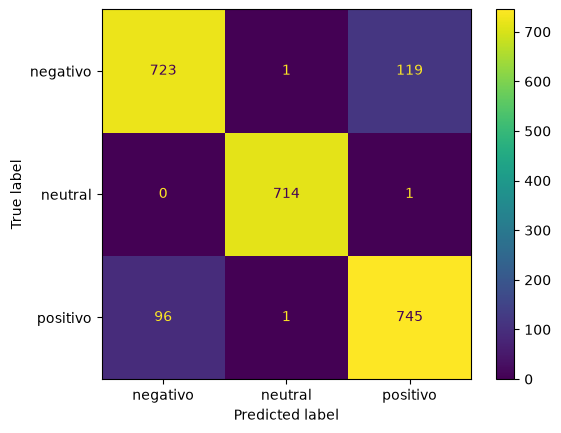

In [11]:
modelo_final = HistGradientBoostingClassifier(
    learning_rate=0.04, max_iter=400, l2_regularization=1.0, random_state=0
)
clases = np.array(sorted(y_train.unique()))

pred_cv = cross_val_predict(modelo_final, R_train, y_train, cv=StratifiedKFold(5, shuffle=True, random_state=7))
modelo_final.fit(R_train, y_train)
pred_test = modelo_final.predict(R_test)

# Referencia: el modelo de texto solo (sus probabilidades son las 3 últimas columnas de los rasgos)
pred_texto_cv = clases[R_train[:, -3:].argmax(axis=1)]
pred_texto_test = clases[R_test[:, -3:].argmax(axis=1)]

print(f"Modelo de texto (LR):  CV {accuracy_score(y_train, pred_texto_cv):.4f} | test {accuracy_score(y_test, pred_texto_test):.4f}")
print(f"Modelo estructurado:   CV {accuracy_score(y_train, pred_cv):.4f} | test {accuracy_score(y_test, pred_test):.4f}")
print(classification_report(y_test, pred_test))
ConfusionMatrixDisplay.from_predictions(y_test, pred_test)
plt.show()

## Resultados por tipo de reseña

Los tipos se definen con `extraer_opiniones` y la etiqueta real (solo para analizar, no como rasgo).

In [12]:
DECISIVOS_ANALISIS = conectores_decisivos(clausulas_train, y_train)


def tipo_de_resena(texto, etiqueta):
    if etiqueta == "neutral":
        return "neutral"
    opiniones = extraer_opiniones(texto)
    if not opiniones:
        return "sin opinión detectada"
    if len({p for _, p, _ in opiniones}) == 1:
        return "una sola polaridad"
    return "mixta, cierre decisivo" if opiniones[-1][2] in DECISIVOS_ANALISIS else "mixta, sin cierre decisivo"


tipos_test = np.array([tipo_de_resena(t, l) for t, l in zip(X_test["text"], y_test)])
pd.DataFrame(
    {
        "reseñas": pd.Series(tipos_test).value_counts(),
        "modelo de texto": pd.Series(pred_texto_test == y_test.to_numpy()).groupby(tipos_test).mean(),
        "modelo estructurado": pd.Series(pred_test == y_test.to_numpy()).groupby(tipos_test).mean(),
    }
).round(3)

,reseñas,modelo de texto,modelo estructurado
"mixta, cierre decisivo",357,0.983,0.994
"mixta, sin cierre decisivo",648,0.755,0.782
neutral,715,0.993,0.999
sin opinión detectada,73,0.863,0.822
una sola polaridad,607,0.860,0.900


## Creación de la submission

Se entrena con todo train (no solo el 80 %) y se predice `data/eval.csv`. Los rasgos de train para el boosting se generan otra vez por folds sobre los 12 000 datos.

In [13]:
eval_data = pd.read_csv("data/eval.csv")
clausulas_todo = X["text"].apply(segmentar)
clausulas_eval = eval_data["text"].apply(segmentar)

folds_todo = list(StratifiedKFold(n_splits=5, shuffle=True, random_state=42).split(X, y))
por_fold = Parallel(n_jobs=len(folds_todo))(
    delayed(rasgos_para)(clausulas_todo.iloc[tr], X.iloc[tr], y.iloc[tr], clausulas_todo.iloc[va], X.iloc[va])
    for tr, va in folds_todo
)
R_todo = np.zeros((len(X), por_fold[0].shape[1]))
for (_, va), rasgos in zip(folds_todo, por_fold):
    R_todo[va] = rasgos
R_eval = rasgos_para(clausulas_todo, X, y, clausulas_eval, eval_data)

modelo_submission = HistGradientBoostingClassifier(
    learning_rate=0.04, max_iter=400, l2_regularization=1.0, random_state=0
).fit(R_todo, y)
pd.DataFrame({"id": eval_data["id"], "answer": modelo_submission.predict(R_eval)}).to_csv(
    "submission_estructurado.csv", index=False
)
print(pd.read_csv("submission_estructurado.csv")["answer"].value_counts())

answer
negativo    1106
positivo    1067
neutral      827
Name: count, dtype: int64
